# Land Use / Land Cover (LULC) Classification of Jaipur
### Multitemporal Sentinel-2 Classification using Spectral Indices & Random Forest

This pipeline ingests Sentinel-2 multispectral Cloud-Optimized GeoTIFFs (COGs), engineers spectral indices (NDVI, NDWI, Soil/Built Ratio), trains a multi-class Random Forest classifier, and quantifies spatial area distribution across Jaipur, Rajasthan.

## 1. Imports and Paths

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import rasterio
from rasterio.features import geometry_mask
from pyproj import Transformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

GEOJSON_PATH = "../data/jaipur_training.geojson"
FCC_PATH = "../outputs/jaipur_fcc_premonsoon.tif"
OUTPUT_TIF = "../outputs/jaipur_lulc_2026.tif"

## 2. Ingest Raster and Compute Spectral Indices

In [2]:
with rasterio.open(FCC_PATH) as src:
    raster_profile = src.profile.copy()
    raw_img = src.read().astype(np.float32)
    transform = src.transform
    crs = src.crs
    res_x, res_y = abs(src.res[0]), abs(src.res[1])

nir, red, green = raw_img[0], raw_img[1], raw_img[2]
eps = 1e-6

# Spectral Indices
ndvi = (nir - red) / (nir + red + eps)
ndwi = (green - nir) / (green + nir + eps)
ratio_rb = (red - green) / (red + green + eps)

feature_stack = np.stack([nir, red, green, ndvi, ndwi, ratio_rb], axis=0)
n_features, height, width = feature_stack.shape
print(f"Feature Stack: {feature_stack.shape} (Bands/Indices, Height, Width)")

Feature Stack: (6, 2200, 2000) (Bands/Indices, Height, Width)


## 3. Sample Training Polygons

In [3]:
with open(GEOJSON_PATH, "r", encoding="utf-8-sig") as f:
    geojson_data = json.load(f)

transformer = Transformer.from_crs("EPSG:4326", crs, always_xy=True)
X_list, y_list = [], []

for feature in geojson_data["features"]:
    class_id = feature["properties"]["class_id"]
    geom_type = feature["geometry"]["type"]
    raw_coords = feature["geometry"]["coordinates"]

    if geom_type == "Polygon":
        projected_coords = [
            [transformer.transform(x, y) for x, y in ring]
            for ring in raw_coords
        ]
        proj_geom = {"type": "Polygon", "coordinates": projected_coords}
        mask = geometry_mask([proj_geom], out_shape=(height, width), transform=transform, invert=True)
        pixels = feature_stack[:, mask].T

        if pixels.shape[0] > 0:
            max_samples = 3000
            if pixels.shape[0] > max_samples:
                idx = np.random.choice(pixels.shape[0], max_samples, replace=False)
                pixels = pixels[idx]
            X_list.append(pixels)
            y_list.append(np.full(pixels.shape[0], class_id))
            print(f"Class {class_id} ({feature['properties']['class_name']}): {pixels.shape[0]} samples")

X = np.vstack(X_list)
y = np.concatenate(y_list)
print(f"Dataset: {X.shape[0]} pixels across 6 spectral dimensions")

Class 1 (Water): 2781 samples
Class 2 (Vegetation): 3000 samples
Class 3 (Built-up): 3000 samples
Class 4 (Barren): 3000 samples
Dataset: 11781 pixels across 6 spectral dimensions


## 4. Train Model and Evaluate Performance

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
rf = RandomForestClassifier(n_estimators=150, max_depth=16, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)
print("=== Classification Report ===")
print(classification_report(y_test, y_pred, digits=4))

print("=== Feature Importances ===")
feature_names = ["NIR", "Red", "Green", "NDVI", "NDWI", "Soil/Built Ratio"]
for name, imp in zip(feature_names, rf.feature_importances_):
    print(f"{name:<18}: {imp*100:.2f}%")

=== Classification Report ===
              precision    recall  f1-score   support

           1     0.9963    0.9784    0.9873       835
           2     0.6655    0.6411    0.6531       900
           3     0.7401    0.7722    0.7558       900
           4     0.5259    0.5311    0.5285       900

    accuracy                         0.7262      3535
   macro avg     0.7320    0.7307    0.7312      3535
weighted avg     0.7271    0.7262    0.7265      3535

=== Feature Importances ===
NIR               : 25.53%
Red               : 15.40%
Green             : 14.38%
NDVI              : 12.74%
NDWI              : 19.68%
Soil/Built Ratio  : 12.27%


## 5. Predict Scene & Calculate Surface Area

In [5]:
flat_stack = feature_stack.reshape(n_features, -1).T
classified_flat = rf.predict(flat_stack)
lulc_map = classified_flat.reshape(height, width)

pixel_area_km2 = (res_x * res_y) / 1e6
class_names = {1: "Water", 2: "Vegetation", 3: "Built-up", 4: "Barren"}
total_pixels = lulc_map.size

print("=== Jaipur Land Cover Statistics ===")
for c_id, name in class_names.items():
    count = np.sum(lulc_map == c_id)
    area_km2 = count * pixel_area_km2
    pct = (count / total_pixels) * 100
    print(f"{name:<12}: {area_km2:>8.2f} km² ({pct:>5.1f}%)")

=== Jaipur Land Cover Statistics ===
Water       :     2.13 km² (  0.5%)
Vegetation  :   237.16 km² ( 53.9%)
Built-up    :    71.19 km² ( 16.2%)
Barren      :   129.52 km² ( 29.4%)


## 6. Thematic Map Visualization

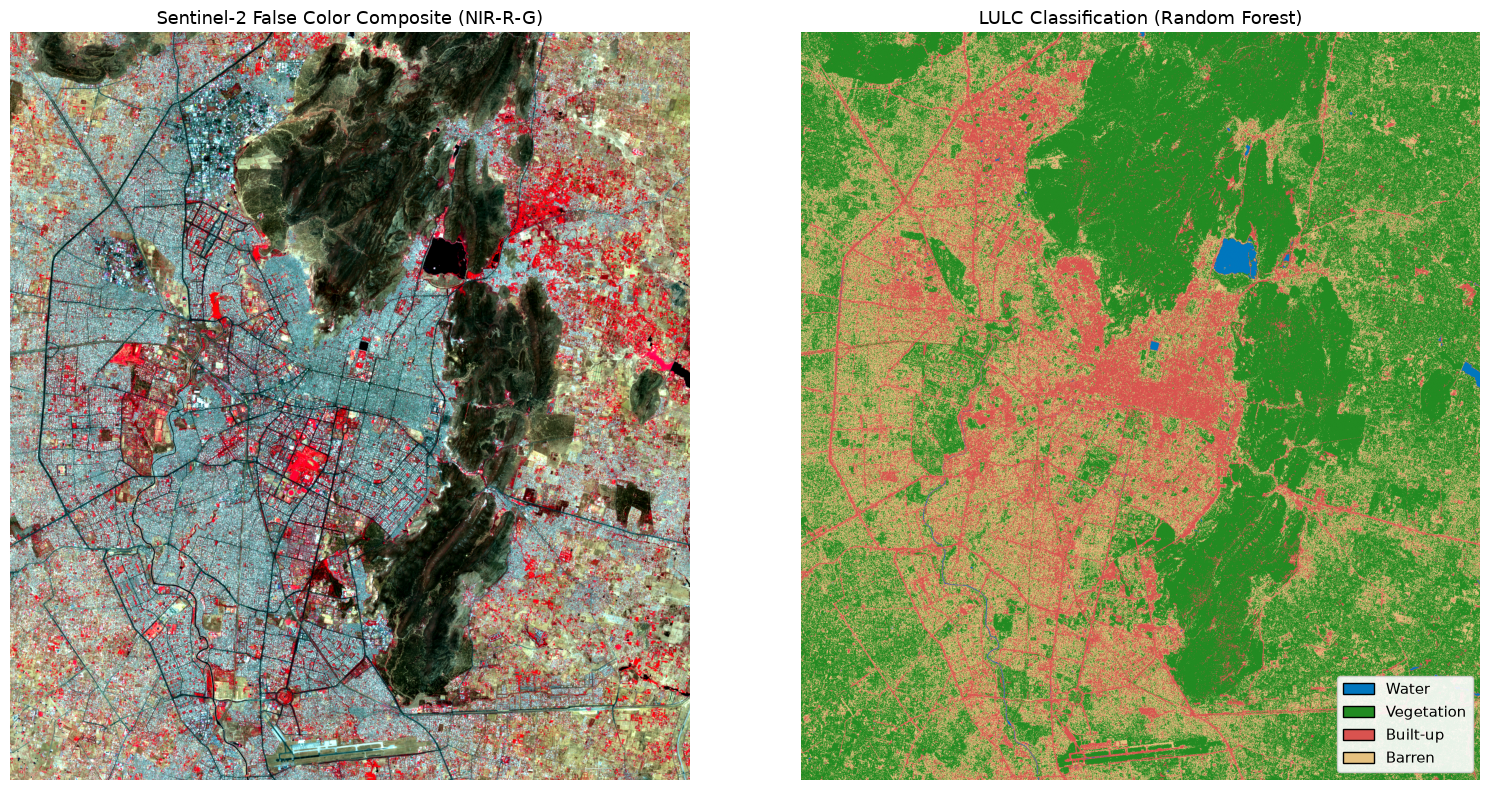

In [6]:
class_colors = ["#0077be", "#228b22", "#d9534f", "#e6c280"]
cmap = ListedColormap(class_colors)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

fcc_display = np.stack([raw_img[0], raw_img[1], raw_img[2]], axis=-1)
for i in range(3):
    p2, p98 = np.percentile(fcc_display[:, :, i], (2, 98))
    fcc_display[:, :, i] = np.clip((fcc_display[:, :, i] - p2) / (p98 - p2 + 1e-6), 0, 1)

axes[0].imshow(fcc_display)
axes[0].set_title("Sentinel-2 False Color Composite (NIR-R-G)", fontsize=13)
axes[0].axis("off")

axes[1].imshow(lulc_map, cmap=cmap, vmin=1, vmax=4)
axes[1].set_title("LULC Classification (Random Forest)", fontsize=13)
axes[1].axis("off")

legend_elements = [Patch(facecolor=class_colors[i], edgecolor='black', label=f"{class_names[i+1]}") for i in range(4)]
axes[1].legend(handles=legend_elements, loc="lower right", framealpha=0.9, fontsize=11)

plt.tight_layout()
plt.show()